In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
data=pd.DataFrame({
    "Study_Hours":[2,4,5,7,8,10],
    "Attendance":[50,60,65,75,85,95],
    "Assignment_Score":[35,45,55,65,80,95],
    "Final_Marks":[38,48,56,68,82,94]
})
display(data)

,Study_Hours,Attendance,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
features=data[[ "Study_Hours","Attendance","Assignment_Score"]]
print("Minimum values:")
print(features.min())



print("Maximum values:")
print(features.max())

Minimum values:
Study_Hours          2
Attendance          50
Assignment_Score    35
dtype: int64
Maximum values:
Study_Hours         10
Attendance          95
Assignment_Score    95
dtype: int64


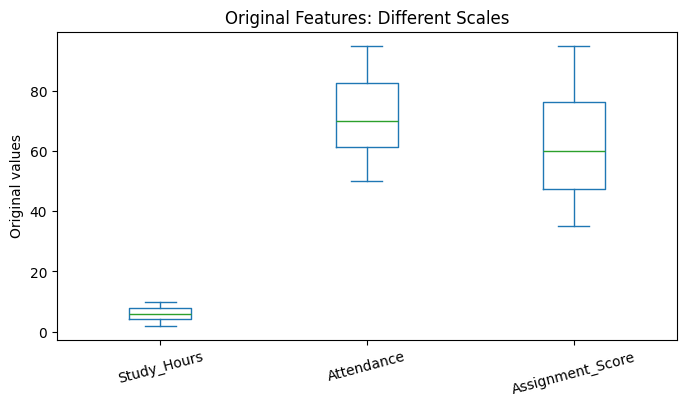

In [ ]:
features.plot(kind="box",figsize=(8,4))
plt.title("Original Features: Different Scales")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
normalizer=MinMaxScaler()
normalized_array=normalizer.fit_transform(features)
normalized_df=pd.DataFrame(
normalized_array,
columns=features.columns,
index=features.index
)
display(normalized_df.round(3))

,Study_Hours,Attendance,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Minimum after normalization:")
print(normalized_df.min())



print("Maximum after normalzation:")
print(normalized_df.max())

Minimum after normalization:
Study_Hours         0.0
Attendance          0.0
Assignment_Score    0.0
dtype: float64
Maximum after normalzation:
Study_Hours         1.0
Attendance          1.0
Assignment_Score    1.0
dtype: float64


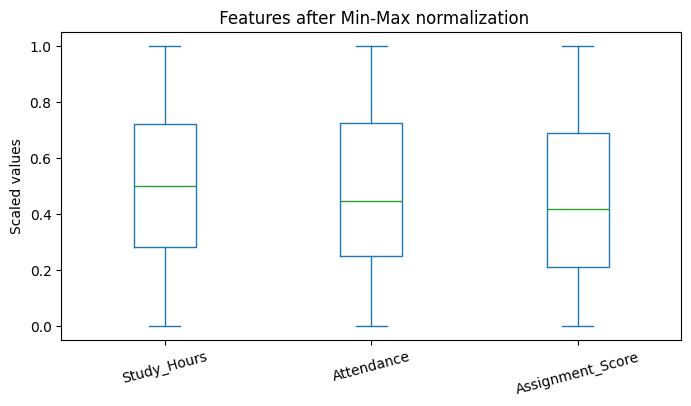

In [ ]:
normalized_df.plot(kind="box",figsize=(8,4))
plt.title(" Features after Min-Max normalization")
plt.ylabel("Scaled values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
standardizer=MinMaxScaler()
standardized_array=standardizer.fit_transform(features)
standardized_df=pd.DataFrame(
standardized_array,
columns=features.columns,
index=features.index
)
display(standardized_df.round(3))

,Study_Hours,Attendance,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Minimum after standardization:")
print(standardized_df.min())



print("Maximum after standardization:")
print(standardized_df.max())

Minimum after standardization:
Study_Hours         0.0
Attendance          0.0
Assignment_Score    0.0
dtype: float64
Maximum after standardization:
Study_Hours         1.0
Attendance          1.0
Assignment_Score    1.0
dtype: float64


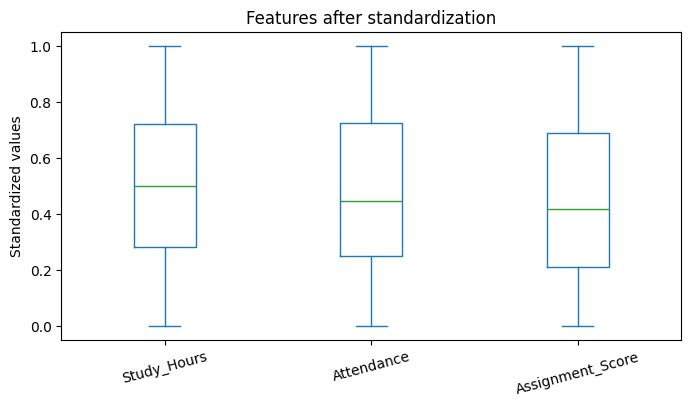

In [ ]:
standardized_df.plot(kind="box",figsize=(8,4))
plt.title("Features after standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
print("Minimum after standardization:")
print(standardized_df.mean().round(6))



print("Maximum after standardization:")
print(standardized_df.std(ddof=0).round(6))

Minimum after standardization:
Study_Hours         0.500000
Attendance          0.481481
Assignment_Score    0.458333
dtype: float64
Maximum after standardization:
Study_Hours         0.330719
Attendance          0.337423
Assignment_Score    0.339355
dtype: float64


In [ ]:
scaled_features=StandardScaler().fit_transform(features)
pca=PCA(n_components=2)
pca_array=pca.fit_transform(scaled_features)
pca_df=pd.DataFrame(
pca_array,
columns=["PC1","PC2"],
index=features.index
)
display(pca_df.round(3))

,PC1,PC2
0,-2.476,-0.115
1,-1.376,0.069
2,-0.684,-0.001
3,0.416,0.182
4,1.440,-0.078
5,2.682,-0.057


In [ ]:
variance_ratios=pca.explained_variance_ratio_
for component,ratio in zip(["PC1","PC2"],variance_ratios):
  print(f"{component} explains {ratio:.2%} of the variance")
total_retained=variance_ratios.sum()
print(f"\Total variance retained by 2 components: {total_retained:.2%}")

PC1 explains 99.62% of the variance
PC2 explains 0.34% of the variance
\Total variance retained by 2 components: 99.96%


<>:5: SyntaxWarning: invalid escape sequence '\T'
<>:5: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_943/1460414221.py:5: SyntaxWarning: invalid escape sequence '\T'
  print(f"\Total variance retained by 2 components: {total_retained:.2%}")


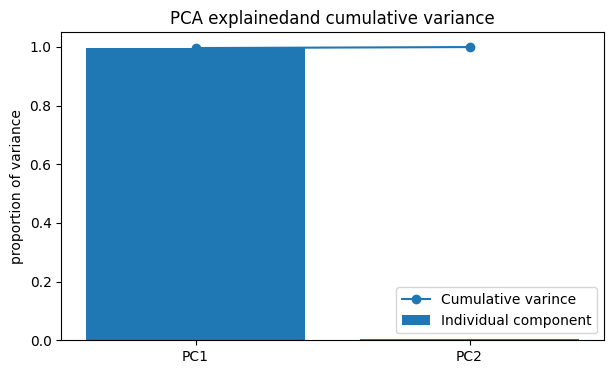

In [ ]:
component_names=["PC1","PC2"]
cumulative_variance=variance_ratios.cumsum()
plt.figure(figsize=(7,4))
plt.bar(component_names,variance_ratios)
plt.plot(component_names,cumulative_variance,marker="o")
plt.ylim(0,1.05)
plt.ylabel("proportion of variance")
plt.title("PCA explainedand cumulative variance")
plt.legend(["Cumulative varince","Individual component"])
plt.show()

In [ ]:
print("Number of original input features:",features.shape[1])
print("Number of PCA components:",pca_df.shape[1])
print("original features shape:",features.shape[1])
print("Reduced PCA data shape:",pca_df.shape[1])


Number of original input features: 3
Number of PCA components: 2
original features shape: 3
Reduced PCA data shape: 2
